In [3]:
from google.colab import files
files.upload()

import pandas as pd, sqlite3
orders = pd.read_csv("orders.csv", dtype=str, keep_default_na=False)
customers = pd.read_csv("customers.csv", dtype=str)
products = pd.read_csv("products.csv", dtype=str)
print(orders.shape)
orders.head()

Saving customers.csv to customers.csv
Saving orders.csv to orders.csv
Saving products.csv to products.csv
(244, 8)


,order_id,order_date,customer_id,product_id,quantity,unit_price,currency,status
0,O0211,2026-09-12,C071,P002,1,7500,INR,completed
1,O0195,2026-09-03,C019,P005,3,900,INR,completed
2,O0051,2026-08-19,,P007,3,1600,INR,completed
3,O0214,2026-09-03,C040,P003,1,6500,INR,completed
4,O0089,2026-08-07,C005,P006,1,4400,INR,completed


In [4]:
print("rows:", len(orders), "| unique ids:", orders.order_id.nunique())
print("exact duplicate rows:", orders.duplicated().sum())
print(orders.status.value_counts())
print(orders.currency.value_counts())
print("blank customer:", (orders.customer_id.str.strip()=="").sum())
print("unknown customer:", (~orders.customer_id.isin(customers.customer_id) & (orders.customer_id!="")).sum())
print("unknown product:", (~orders.product_id.isin(products.product_id)).sum())

rows: 244 | unique ids: 240
exact duplicate rows: 3
status
completed      211
refunded        16
cancelled       15
 Completed       1
COMPLETE         1
Name: count, dtype: int64
currency
INR    242
EUR      1
USD      1
Name: count, dtype: int64
blank customer: 2
unknown customer: 2
unknown product: 2


In [6]:
raw = ["order_id","order_date","customer_id","product_id","quantity","unit_price","currency","status"]
orders = orders.drop_duplicates(subset=raw)
dup_ids = orders.order_id[orders.order_id.duplicated(keep=False)]
print("conflicting ids:", dup_ids.unique())

conflicting ids: ['O0089']


In [8]:
print(orders.columns.tolist())

['order_id', 'order_date', 'customer_id', 'product_id', 'quantity', 'unit_price', 'currency', 'status']


In [9]:
orders["status_norm"] = orders.status.str.strip().str.lower()
orders["currency_norm"] = orders.currency.str.strip().str.upper()
orders["qty"] = pd.to_numeric(orders.quantity, errors="coerce")
orders["price"] = pd.to_numeric(orders.unit_price, errors="coerce")

d1 = pd.to_datetime(orders.order_date, format="%Y-%m-%d", errors="coerce")
d2 = pd.to_datetime(orders.order_date, format="%Y/%m/%d", errors="coerce")
orders["dt"] = d1.fillna(d2)

print(orders.columns.tolist())

['order_id', 'order_date', 'customer_id', 'product_id', 'quantity', 'unit_price', 'currency', 'status', 'status_norm', 'currency_norm', 'qty', 'price', 'dt']


In [10]:
raw = ["order_id","order_date","customer_id","product_id","quantity","unit_price","currency","status"]
orders = orders.drop_duplicates(subset=raw)
dup_ids = orders.order_id[orders.order_id.duplicated(keep=False)]
print("rows after removing exact copies:", len(orders))
print("conflicting ids:", dup_ids.unique())

rows after removing exact copies: 241
conflicting ids: ['O0089']


In [11]:
valid_cust = set(customers.customer_id)
valid_prod = set(products.product_id)
conflict_ids = set(dup_ids)

def reason(r):
    if r["order_id"] in conflict_ids: return "conflicting_duplicate"
    if pd.isna(r["dt"]): return "invalid_date"
    if r["customer_id"] == "": return "missing_customer"
    if r["customer_id"] not in valid_cust: return "unknown_customer"
    if r["product_id"] not in valid_prod: return "unknown_product"
    if not r["qty"] > 0: return "bad_quantity"
    if not r["price"] > 0: return "bad_price"
    if r["currency_norm"] not in ("INR", "USD"): return "unsupported_currency"
    if r["status_norm"] in ("cancelled", "refunded"): return "excluded_status"
    if r["status_norm"] != "completed": return "ambiguous_status"
    return None

orders["reject_reason"] = orders.apply(reason, axis=1)
print(orders.reject_reason.value_counts(dropna=False))

reject_reason
None                     197
excluded_status           29
missing_customer           2
conflicting_duplicate      2
invalid_date               2
unknown_customer           2
bad_quantity               2
unknown_product            2
bad_price                  1
ambiguous_status           1
unsupported_currency       1
Name: count, dtype: int64


In [12]:
orders["unit_price_inr"] = orders.price * orders.currency_norm.map({"INR": 1, "USD": 85})
orders["revenue_inr"] = orders.qty * orders.unit_price_inr
orders["month"] = orders.dt.dt.strftime("%Y-%m")
orders["order_date_clean"] = orders.dt.dt.strftime("%Y-%m-%d")

clean = orders[orders.reject_reason.isna()].copy()
clean["first_order_date"] = clean.groupby("customer_id").order_date_clean.transform("min")
rejected = orders[orders.reject_reason.notna()].copy()

clean.to_csv("clean_orders.csv", index=False)
rejected.to_csv("rejected_orders.csv", index=False)
print(len(clean), "clean |", len(rejected), "rejected")

197 clean | 44 rejected


In [13]:
slim = clean[["order_id","order_date_clean","month","customer_id","product_id",
              "quantity","unit_price_inr","revenue_inr","first_order_date"]]
slim = slim.rename(columns={"order_date_clean":"order_date"})
slim.to_csv("clean_orders_slim.csv", index=False)
files.download("clean_orders_slim.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:
from google.colab import files
import pandas as pd
import matplotlib.pyplot as plt

files.upload()   # choose clean_orders_slim.csv (or clean_orders.csv)

fname = "clean_orders_slim.csv"   # change to clean_orders.csv if you uploaded that one
clean = pd.read_csv(fname)
print(clean.shape)               # should be (197, ...)
clean[["month", "product_id", "revenue_inr"]].head()

Saving result of drive.csv to result of drive.csv
(197, 9)


,month,product_id,revenue_inr
0,2026-09,P002,7500.0
1,2026-09,P005,2700.0
2,2026-09,P003,6500.0
3,2026-08,P012,15000.0
4,2026-08,P005,900.0


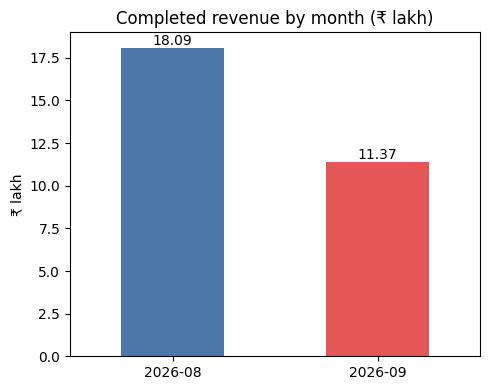

In [16]:
m = clean.groupby("month").revenue_inr.sum() / 100000
ax = m.plot(kind="bar", color=["#4C78A8", "#E45756"], figsize=(5, 4))
ax.set_title("Completed revenue by month (₹ lakh)")
ax.set_ylabel("₹ lakh"); ax.set_xlabel("")
for i, v in enumerate(m):
    ax.text(i, v, f"{v:.2f}", ha="center", va="bottom")
plt.xticks(rotation=0); plt.tight_layout()
plt.savefig("chart1_monthly_revenue.png", dpi=150); plt.show()

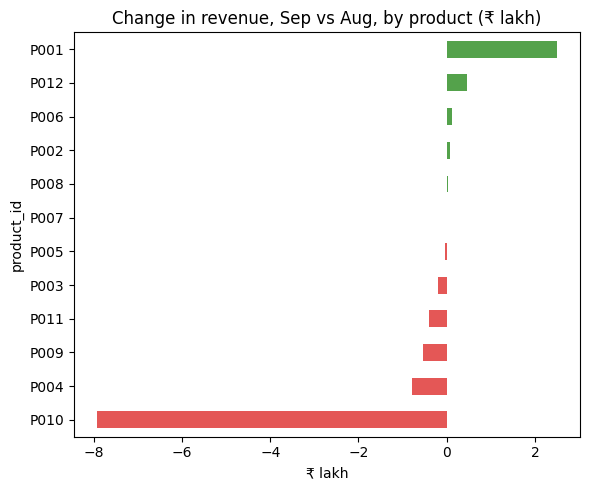

In [17]:
p = clean.pivot_table(index="product_id", columns="month",
                      values="revenue_inr", aggfunc="sum", fill_value=0)
change = ((p["2026-09"] - p["2026-08"]) / 100000).sort_values()
ax = change.plot(kind="barh",
                 color=["#E45756" if v < 0 else "#54A24B" for v in change],
                 figsize=(6, 5))
ax.set_title("Change in revenue, Sep vs Aug, by product (₹ lakh)")
ax.set_xlabel("₹ lakh")
plt.tight_layout()
plt.savefig("chart2_product_change.png", dpi=150); plt.show()

In [18]:
files.download("chart1_monthly_revenue.png")
files.download("chart2_product_change.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>